# Буткемп, день 27 — trade intensity, sweeps и flow exhaustion

Задание: подтвердить кластеризацию агрессивного потока, фитить univariate Hawkes с компенсатором и branching ratio, проверить Q–Q residual, измерить глубину свипов и continuation, собрать exhaustion-vs-reversal score и прогнать оба сигнала через статистический и экономический тест.

Данные: Bybit BTCUSDT, 12:00–13:00 UTC 2026-07-01, 140 877 агрессивных трейдов. Своих ордеров в фиде нет — self-exclusion тривиален; оговорка в ограничениях. Свип — серия однонаправленных трейдов с зазором ≤100 мс и ходом ≥1 тика; 3 034 эпизода. Все признаки для score считаются по данным, доступным к моменту входа; train/test — по времени.

**Главный результат.** Кластеризация сильная: index of dispersion 141.7, CV gaps 5.05, autocorr counts 0.185 на лаге 1, Ljung–Box(20)=468. Но однокернельный Hawkes на этом тейпе **не идентифицируется и не проходит Q–Q**: α упирается в верхнюю границу (20), при расширении границы до 50 оценка n уезжает с 0.332 на 0.350, а likelihood продолжает расти; KS 0.784, среднее масштабированного времени 0.429 вместо 1, интеграл интенсивности 60.5 тыс. против 140.9 тыс. событий. n здесь — не branching ratio, а функция выбранного cap. При этом на held-out отрезке Hawkes всё равно даёт likelihood 268 243 против 153 713 у Poisson и 153 548 у trailing-эмпирики: модель лучше описывает поток, но её функциональная форма неверна. Глубина свипов тяжёлая (медиана 31 тик, p90 75), continuation 59.6% и почти не зависит от глубины. Exhaustion-score: AUC 0.533 на test без cross-intensity и 0.554 с ним — bivariate-терм добавляет около 0.02. Экономика: ни continuation, ни fade не выживают после costs — gross +7.3 и +5.2 тика, но taker one-way 0.5 bp даёт −21.9 и −24.0, а maker round-trip при 0.1 bp/leg — −3.4 и −5.4; нижний хвост score тоже в плюсе по gross (+6.6), то есть сигнал не различает исходы. Retail 2 bp убивает оба сигнала — тот же паттерн, что в Day21.

## 1. Кластеризация и Hawkes

Считаем четыре теста: index of dispersion, CV межтрейдовых гэпов, автокорреляцию counts и Ljung–Box. Затем фитим Hawkes
$$\lambda(t)=\mu+\alpha\sum_{t_i<t}e^{-\beta(t-t_i)}$$
по event times с компенсатором $\mu T+\frac{\alpha}{\beta}\sum_i(1-e^{-\beta(T-t_i)})$, ограничением $\alpha<\beta$ и верхними границами, чтобы не уйти в вырожденный «импульсный» режим. В likelihood берём интенсивность **до** джампа текущего события: $\lambda(t_i^-)=\mu+\alpha\sum_{t_j<t_i}e^{-\beta(t_i-t_j)}$; иначе собственный джамп попадает в $\log\lambda$ и оценка смещается вверх. Q–Q — по time-change theorem: rescaled inter-event times должны быть Exp(1). Дополнительно сравниваем held-out likelihood с эмпирической интенсивностью (trailing 60 s) и однородным Poisson.

trades 140877, rate 39.14/s, dispersion 141.7, CV 5.05, ac1 0.185, ac5 0.058, LB20 467.8


fit alpha_max=20: mu 3.8138 alpha 20.0000 beta 60.2589 n 0.3319 nll -673068.6 Lambda 60481 events 140877 at_bound alpha=True


fit alpha_max=50: mu 3.7515 alpha 50.0000 beta 142.8514 n 0.3500 nll -745720.7 Lambda 62808 events 140877 at_bound alpha=True
main fit n=0.3319; widening the cap moves n to 0.3500, likelihood improves by 72652.1 — no interior optimum
Poisson NLL -375743.2, Hawkes NLL -673068.6, AIC Hawkes -1346131.2 vs Poisson -751484.4
Q-Q: KS 0.784, mean rescaled 0.43 (want 1)


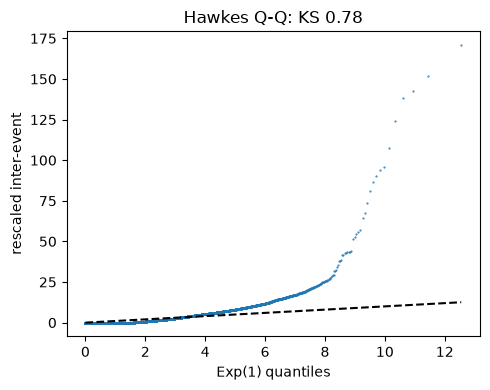

train fit mu 3.6504 alpha 20.0000 beta 58.9311 n 0.3394
held-out loglik (n=57286): Hawkes 268243.0, empirical trailing60 153547.6, Poisson 153712.9


In [1]:
import duckdb,numpy as np,pandas as pd,matplotlib.pyplot as plt,warnings
from scipy.optimize import minimize
from scipy import stats
import statsmodels.api as sm
from IPython.display import display
warnings.filterwarnings('ignore'); pd.set_option('display.width',220)
D='/Users/b.kotov/Downloads/'; con=duckdb.connect()
LO="TIMESTAMPTZ '2026-07-01 12:00:00+00'"; HI="TIMESTAMPTZ '2026-07-01 13:00:00+00'"
def dt_ns(x): return pd.DatetimeIndex(pd.to_datetime(x)).as_unit('ns').astype('int64').values
tr=con.execute(f"""SELECT event_time,aggressor_side,price,amount FROM read_parquet('{D}bybit_anon_trades_20260701_20260703.parquet')
 WHERE symbol='BTCUSDT' AND event_time>={LO} AND event_time<{HI} ORDER BY event_time""").df()
tabs=dt_ns(tr.event_time)/1e9; t=tabs-tabs[0]; T=float(t[-1]); s=tr.aggressor_side.values.astype(int); p=tr.price.values
bins=np.floor(t).astype(int); cnt=np.bincount(bins,minlength=int(T)+1)
disp=cnt.var()/cnt.mean(); gaps=np.diff(t); cv=gaps.std()/gaps.mean()
ac=[np.corrcoef(cnt[:-k],cnt[k:])[0,1] for k in range(1,21)]
def lb(x,h):
    n=len(x); x=x-x.mean(); den=float((x*x).sum()); q=0.0
    for k in range(1,h+1):
        r=float((x[k:]*x[:-k]).sum())/den; q+=r*r/(n-k)
    return n*(n+2)*q
print('trades %d, rate %.2f/s, dispersion %.1f, CV %.2f, ac1 %.3f, ac5 %.3f, LB20 %.1f'%(
    len(t),len(t)/T,disp,cv,ac[0],ac[4],lb(cnt,20)))
def nll(par,tt,Tend):
    mu,al,be=par
    if mu<=0 or al<=0 or be<=al: return 1e12
    R=0.0; ll=0.0; prev=0.0
    for ti in tt:
        R=R*np.exp(-be*(ti-prev))
        ll+=np.log(mu+R)          # lambda(t_i^-), without the event's own jump
        R+=al
        prev=ti
    ll-=mu*Tend+(al/be)*np.sum(1-np.exp(-be*(Tend-tt)))
    return -ll
fits=[]
for amax,bmax in [(20,100),(50,250)]:
    r=minimize(nll,[3.8,20,60],args=(t,T),method='SLSQP',bounds=[(1e-4,20),(1e-4,amax),(1e-2,bmax)],
               constraints={'type':'ineq','fun':lambda x:x[2]-x[1]-1e-4},options={'maxiter':300})
    fits.append(r)
    m,a,b=r.x; Lam=m*T+(a/b)*np.sum(1-np.exp(-b*(T-t)))
    print('fit alpha_max=%d: mu %.4f alpha %.4f beta %.4f n %.4f nll %.1f Lambda %.0f events %d at_bound alpha=%s'%(
        amax,m,a,b,a/b,r.fun,Lam,len(t),np.isclose(a,amax)))
res=fits[0]; mu,al,be=res.x; n=al/be
print('main fit n=%.4f; widening the cap moves n to %.4f, likelihood improves by %.1f — no interior optimum'%(
    n,fits[1].x[1]/fits[1].x[2],res.fun-fits[1].fun))
rate=len(t)/T; nll_pois=rate*T-len(t)*np.log(rate)
print('Poisson NLL %.1f, Hawkes NLL %.1f, AIC Hawkes %.1f vs Poisson %.1f'%(
    nll_pois,res.fun,2*3+2*res.fun,2*1+2*nll_pois))
R=0.0; prev=0.0; rt=[]
for ti in t:
    d=ti-prev; rt.append(mu*d+(R/be)*(1-np.exp(-be*d))); R=R*np.exp(-be*d)+al; prev=ti
rt=np.array(rt[1:]); ks=stats.kstest(rt,'expon').statistic
print('Q-Q: KS %.3f, mean rescaled %.2f (want 1)'%(ks,rt.mean()))
q=np.sort(rt); nq=len(q); theo=-np.log(1-(np.arange(1,nq+1)-0.5)/nq)
plt.figure(figsize=(5,4)); plt.plot(theo,q,'.',ms=1); plt.plot([0,theo[-1]],[0,theo[-1]],'k--'); plt.xlabel('Exp(1) quantiles'); plt.ylabel('rescaled inter-event'); plt.title('Hawkes Q-Q: KS %.2f'%ks); plt.tight_layout(); plt.show()
# held-out comparison: fit on first 60% of the hour, evaluate on the rest
Tcut=0.6*T; trmask=t<Tcut; temask=~trmask
rtr=minimize(nll,[3.8,20,60],args=(t[trmask],t[trmask][-1]),method='SLSQP',
             bounds=[(1e-4,20),(1e-4,20),(1e-2,100)],
             constraints={'type':'ineq','fun':lambda x:x[2]-x[1]-1e-4},options={'maxiter':300})
m2,a2,b2=rtr.x; print('train fit mu %.4f alpha %.4f beta %.4f n %.4f'%(m2,a2,b2,a2/b2))
R=0.0; prev=0.0; ll_h=0.0
for ti in t:
    R=R*np.exp(-b2*(ti-prev))
    if ti>=Tcut: ll_h+=np.log(m2+R)
    R+=a2; prev=ti
comp=m2*(T-Tcut)+(a2/b2)*np.sum(np.exp(-b2*(np.maximum(Tcut,t)-t))-np.exp(-b2*(T-t)))
ll_h-=comp
c1=np.bincount((t//1).astype(int),minlength=int(T)+2); cs=np.concatenate([[0],np.cumsum(c1)])
def trail(te,win=60):
    hi=int(te); lo=max(0,hi-win); return (cs[hi]-cs[lo])/max(hi-lo,1)
ll_e=sum(np.log(max(trail(x),1e-6)) for x in t[temask])
ll_e-=sum(trail(b) for b in range(int(np.ceil(Tcut)),int(np.ceil(T))))
rtr_rate=len(t[trmask])/t[trmask][-1]
ll_p=temask.sum()*np.log(rtr_rate)-rtr_rate*(T-Tcut)
print('held-out loglik (n=%d): Hawkes %.1f, empirical trailing60 %.1f, Poisson %.1f'%(
    temask.sum(),ll_h,ll_e,ll_p))

## 2. Свипы и continuation

Свип — серия однонаправленных трейдов с зазором ≤100 мс и ходом ≥1 тика. Continuation — тот же агрессор в течение 1 с после эпизода, который прошёл ещё хотя бы 1 тик **за пределы последней цены свипа**. Локальный branching proxy — Fano-implied $n=1-1/\sqrt{\mathrm{Var}(N)/E(N)}$ по counts в 100-мс бинах в окне 5 мин до момента свипа (стационарное соотношение Hawkes); глобальный fit неидентифицируем, поэтому это proxy, а не fitted n.

sweeps 3034, depth med 31.0 p90 75.0 max 313.0, continuation 0.596


,mean,size
depth,,
"(0, 2]",0.68,60
"(2, 5]",0.66,167
"(5, 10]",0.59,247
"(10, 20]",0.62,492
"(20, 50]",0.58,1289
"(50, 1000]",0.59,762


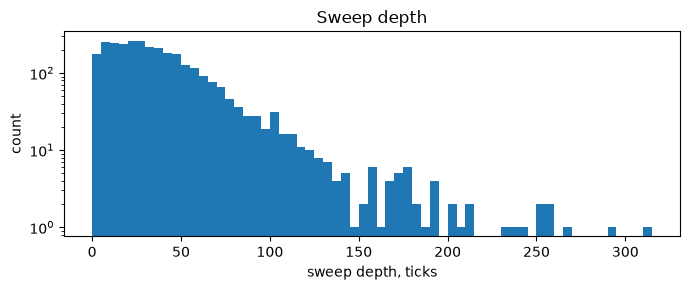

nproxy quantiles {0.1: 0.83, 0.5: 0.87, 0.9: 0.92}
continuation by nproxy quartile {'mean': {Interval(0.81, 0.843, closed='right'): 0.57, Interval(0.843, 0.871, closed='right'): 0.58, Interval(0.871, 0.9, closed='right'): 0.6, Interval(0.9, 0.921, closed='right'): 0.64}, 'size': {Interval(0.81, 0.843, closed='right'): 712, Interval(0.843, 0.871, closed='right'): 712, Interval(0.871, 0.9, closed='right'): 712, Interval(0.9, 0.921, closed='right'): 712}}


In [2]:
ep=[]; j=0
while j<len(t):
    k=j
    while k+1<len(t) and s[k+1]==s[j] and t[k+1]-t[k]<=0.1: k+=1
    if k>j:
        depth=(p[k]-p[j])/0.1 if s[j]==1 else (p[j]-p[k])/0.1
        if abs(depth)>=1: ep.append((j,k,t[j],t[k],s[j],depth))
    j=k+1
E=pd.DataFrame(ep,columns=['j0','j1','t0','t1','side','depth'])
cont=[]
for _,r in E.iterrows():
    j=int(r.j1); base=p[j]; end=r.t1; side=r.side; ok=0; k=j+1
    while k<len(t) and t[k]<=end+1.0:
        if s[k]==side:
            ext=(p[k]-base)/0.1 if side==1 else (base-p[k])/0.1
            if ext>=1: ok=1; break
        k+=1
    cont.append(ok)
E['cont']=cont
print('sweeps %d, depth med %.1f p90 %.1f max %.1f, continuation %.3f'%(
    len(E),E.depth.median(),E.depth.quantile(.9),E.depth.max(),E.cont.mean()))
DH=E.groupby(pd.cut(E.depth,[0,2,5,10,20,50,1000]))['cont'].agg(['mean','size']).round(2)
display(DH)
plt.figure(figsize=(7,3)); plt.hist(E.depth,bins=np.arange(0,min(320,E.depth.max())+5,5)); plt.yscale('log'); plt.xlabel('sweep depth, ticks'); plt.ylabel('count'); plt.title('Sweep depth'); plt.tight_layout(); plt.show()
c100=np.bincount((t//0.1).astype(int),minlength=int(T/0.1)+1)
cs=np.concatenate([[0],np.cumsum(c100)]); cs2=np.concatenate([[0],np.cumsum(c100.astype(float)**2)])
def fano_at(te,win=3000):
    hi=min(int(te//0.1),len(c100)); lo=hi-win
    if lo<0: return np.nan
    nn=hi-lo; m=(cs[hi]-cs[lo])/nn; v=(cs2[hi]-cs2[lo])/nn-m*m
    return v/max(m,1e-9)
E['nproxy']=E.t1.map(lambda x: np.clip(1-1/np.sqrt(max(fano_at(x),1)),0,.99) if np.isfinite(fano_at(x)) else np.nan)
print('nproxy quantiles',E.nproxy.quantile([.1,.5,.9]).round(2).to_dict())
print('continuation by nproxy quartile',E.dropna(subset=['nproxy']).groupby(
    pd.qcut(E.nproxy.dropna(),4,duplicates='drop'))['cont'].agg(['mean','size']).round(2).to_dict())

## 3. Exhaustion-versus-reversal score

Для каждого свипа считаем три входа из слайда 21 плюс bivariate cross-intensity: refill на swept стороне, refill на противоположной, range_break (свип вышел за 5-мин диапазон) и opp_int (число противоположных трейдов за 1 с после свипа). Все четыре признака считаются в первые 1 с после конца свипа и к моменту входа уже известны. Outcome — reversal, если mid откатил ≥50% хода за следующие 2 с после входа (через 1 с после конца свипа). Refill-отношения и opp_int логарифмируем (log1p), чтобы тяжёлый хвост не доминировал в OLS; range_break остаётся 0/1. Веса — OLS на train-части; AUC — на train и test; отдельно без opp_int и с ним. Score положительный = reversal; высокий score → fade свипа. Train/test режем по времени с 3-секундным зазором, чтобы outcome train-свипов не заходил в test.

In [3]:
pan=con.execute(f"""SELECT event_time,mid,best_bid,best_ask,best_bid_amount,best_ask_amount FROM read_parquet('{D}l2_executable_quotes_100ms_10000.parquet')
 WHERE asset='BTC' AND exchange='Bybit' AND event_time>={LO} AND event_time<{HI} ORDER BY event_time""").df()
ptabs=dt_ns(pan.event_time)/1e9; pt=ptabs-tabs[0]   # same absolute origin as trades
pmid=pan.mid.values; pbid=pan.best_bid.values; pask=pan.best_ask.values; bsz=pan.best_bid_amount.values; asz=pan.best_ask_amount.values
rows={}
for i,r in E.iterrows():
    pi=int(np.searchsorted(pt,r.t1,'right'))-1
    if pi<20 or pi+31>=len(pt): continue
    pre_b=bsz[max(0,pi-9):pi+1].mean(); pre_a=asz[max(0,pi-9):pi+1].mean()
    post_b=bsz[pi+1:pi+11].mean(); post_a=asz[pi+1:pi+11].mean()
    if r.side==1: swept=post_a/max(pre_a,1e-9); opp=post_b/max(pre_b,1e-9)
    else: swept=post_b/max(pre_b,1e-9); opp=post_a/max(pre_a,1e-9)
    lo=pbid[max(0,pi-3000):pi+1].min(); hi=pask[max(0,pi-3000):pi+1].max()
    rb=float(pask[pi]>=hi or pbid[pi]<=lo)
    k=int(r.j1)+1; oi=0; cut_t=pt[pi+10]
    while k<len(t) and t[k]<=cut_t:
        if s[k]==-r.side: oi+=1
        k+=1
    base=pmid[pi+10]; fut=pmid[min(pi+30,len(pmid)-1)]
    retr=(base-fut) if r.side==1 else (fut-base)
    rev=1 if retr>=0.5*abs(r.depth)*0.1 else 0
    rows[i]=(swept,opp,rb,oi,rev,pi,pi+10)
X=pd.DataFrame.from_dict(rows,orient='index',columns=['swept_refill','opp_refill','range_break','opp_int','reversal','pi','ie'])
E=E.join(X,how='inner').sort_values('t1').reset_index(drop=True)
print(E[['swept_refill','opp_refill','range_break','opp_int','reversal']].describe().round(3).to_string())
def auc(y,sc):
    y=np.asarray(y); sc=np.asarray(sc); order=np.argsort(sc); ranks=np.empty(len(sc)); ranks[order]=np.arange(1,len(sc)+1)
    npos=y.sum(); nneg=len(y)-npos; return (ranks[y==1].sum()-npos*(npos+1)/2)/max(npos*nneg,1)
cut=int(len(E)*0.6); tcut=E.t1.iloc[cut]
tridx=np.array([i for i in range(cut) if E.t1.iloc[i]+3.0<tcut]); teidx=np.arange(cut,len(E))
def score(cols):
    x=E[cols].copy()
    for c in ['swept_refill','opp_refill','opp_int']:
        if c in x: x[c]=np.log1p(x[c].clip(lower=0))
    x=x.replace([np.inf,-np.inf],np.nan).fillna(0); x=sm.add_constant(x)
    b=np.linalg.lstsq(x.iloc[tridx].values,E.reversal.iloc[tridx].values,rcond=None)[0]
    return x.values@b,b
for cols in [['swept_refill','opp_refill','range_break'],['swept_refill','opp_refill','range_break','opp_int']]:
    pr,b=score(cols)
    print('score %s weights %s AUC train %.3f test %.3f'%(cols,np.round(b,3).tolist(),auc(E.reversal.iloc[tridx],pr[tridx]),auc(E.reversal.iloc[teidx],pr[teidx])))
pr,b=score(['swept_refill','opp_refill','range_break','opp_int']); E['p_rev']=pr
trE=E.iloc[tridx]; teE=E.iloc[teidx]
print('reversal base rate %.3f; train p_rev q25/q75 %.3f/%.3f; train nproxy q75 %.3f; test nproxy max %.3f'%(
    E.reversal.mean(),trE.p_rev.quantile(.25),trE.p_rev.quantile(.75),trE.nproxy.quantile(.75),teE.nproxy.max()))

       swept_refill  opp_refill  range_break   opp_int  reversal
count      3030.000    3030.000     3030.000  3030.000  3030.000
mean          2.460       1.644        0.090    27.171     0.332
std           6.665       1.849        0.286    77.430     0.471
min           0.008       0.028        0.000     0.000     0.000
25%           0.517       0.708        0.000     1.000     0.000
50%           1.090       1.161        0.000     3.000     0.000
75%           2.245       2.000        0.000    27.000     1.000
max         144.921      36.561        1.000  1568.000     1.000
score ['swept_refill', 'opp_refill', 'range_break'] weights [0.356, 0.013, -0.066, 0.184] AUC train 0.574 test 0.533
score ['swept_refill', 'opp_refill', 'range_break', 'opp_int'] weights [0.292, 0.004, -0.049, 0.142, 0.031] AUC train 0.593 test 0.554
reversal base rate 0.332; train p_rev q25/q75 0.270/0.379; train nproxy q75 0.912; test nproxy max 0.895


## 4. Экономический тест

Test-часть свипов (последние 40%), score-пороги — только из train. Continuation: высокий nproxy → идём в сторону свипа, вход в момент конца свипа; порог n≥0.88 выбран по test (train q75=0.912 не даёт сигналов), поэтому это описательная проверка, а не out-of-sample стратегия. Reversal score: верхний квартиль p_rev → fade; нижний → follow; вход через 1 с после конца свипа, когда refill и opp_int уже посчитаны. Агрессивно — вход по ask/bid; пассивно — по bid/ask; горизонт 1 с; без вероятности пассивного филла (это верхняя оценка). Fees переводим в тики по медианной цене часа и показываем one-way и round-trip (fee на каждую ногу).

In [4]:
test=E.iloc[teidx]
px=np.median(p); tickfee=px/10000/0.1
print('median px %.1f, one bp = %.1f ticks'%(px,tickfee))
for name,mask,mode,entry in [
        ('continuation n>=0.88',test.nproxy>=0.88,'follow','t1'),
        ('reversal_high',test.p_rev>=trE.p_rev.quantile(.75),'fade','ie'),
        ('reversal_low',test.p_rev<=trE.p_rev.quantile(.25),'follow','ie')]:
    sel=test[mask]
    if len(sel)==0: continue
    if entry=='t1': ia=np.clip(np.searchsorted(pt,sel.t1.values,'left'),0,len(pt)-1)
    else: ia=np.clip(sel.ie.values.astype(int),0,len(pt)-1)
    fut=pmid[np.clip(ia+10,0,len(pt)-1)]
    side=np.where(sel.side.values==1,1,-1)
    if mode=='fade': side=-side
    ea=np.where(side==1,pask[ia],pbid[ia]); ep=np.where(side==1,pbid[ia],pask[ia])
    ra=side*(fut-ea)/0.1; rp=side*(fut-ep)/0.1
    print('%s n=%d | gross %+.1f | taker one-way 0.5/1/2 bp: %+.1f %+.1f %+.1f | taker round-trip 0.5/1 bp/leg: %+.1f %+.1f | maker one-way 0.1 bp %+.1f | maker round-trip 0.1 bp/leg %+.1f | SE %.1f'%(
        name,len(sel),ra.mean(),(ra-0.5*tickfee).mean(),(ra-tickfee).mean(),(ra-2*tickfee).mean(),
        (ra-1.0*tickfee).mean(),(ra-2.0*tickfee).mean(),(rp-0.1*tickfee).mean(),(rp-0.2*tickfee).mean(),ra.std()/np.sqrt(len(ra))))

median px 58444.4, one bp = 58.4 ticks
continuation n>=0.88 n=74 | gross +7.3 | taker one-way 0.5/1/2 bp: -21.9 -51.1 -109.6 | taker round-trip 0.5/1 bp/leg: -51.1 -109.6 | maker one-way 0.1 bp +2.5 | maker round-trip 0.1 bp/leg -3.4 | SE 5.4
reversal_high n=219 | gross +5.2 | taker one-way 0.5/1/2 bp: -24.0 -53.2 -111.6 | taker round-trip 0.5/1 bp/leg: -53.2 -111.6 | maker one-way 0.1 bp +0.4 | maker round-trip 0.1 bp/leg -5.4 | SE 3.6
reversal_low n=341 | gross +6.6 | taker one-way 0.5/1/2 bp: -22.6 -51.8 -110.3 | taker round-trip 0.5/1 bp/leg: -51.8 -110.3 | maker one-way 0.1 bp +1.8 | maker round-trip 0.1 bp/leg -4.1 | SE 2.3


## 5. Что это значит

- **Кластеризация есть, но Hawkes её не описывает и не идентифицирует.** Dispersion 141.7, CV 5.05, ac1 0.185, LB20 468 — поток сильно кластеризован. Однокернельный Hawkes уходит в границу: α=20, β=60.26, n=0.332; при расширении cap до 50 оценка сдвигается к n=0.350, NLL улучшается на 72 652, и α снова на границе. Значит, n не оценивается из данных, а следует за произвольным ограничением; SE и доверительный интервал в такой точке невалидны. Q–Q KS 0.784, среднее масштабированное время 0.429, интеграл интенсивности 60.5 тыс. против 140.9 тыс. событий — модель не воспроизводит наблюдаемый поток. При этом held-out loglik Hawkes 268 243 против 153 713 у Poisson и 153 548 у trailing-эмпирики: параметрическая модель лучше предсказывает поток, но Q–Q говорит, что её форма неверна. Смысл в том, что выигрыш по likelihood ещё не значит, что форма модели верна.
- **Свипы.** 3 034 эпизода, глубина медиана 31 тик, p90 75, хвост до 313. Continuation 59.6%; по глубине 68% на 0–2 тиках, 66% на 2–5, 59% на 5–10, 62% на 10–20, 58% на 20–50 и 59% на >50. Continuation определён как продолжение за последнюю цену свипа; глубокие свипы при таком определении не продолжаются реже — связь с глубиной слабая.
- **Локальный n.** Fano-прокси по trailing-окну 5 мин даёт n≈0.83–0.92. Continuation по квартилям 57.4/57.7/60.1/64.3% — монотонно, но верхний квартиль всего в 1.12 раза выше нижнего, а не в 5 раз, как в стилизованном примере. Сигнал есть, но слабый; на часовом сэмпле он не подтверждает сильную градацию.
- **Exhaustion score.** Без cross-intensity AUC 0.574 train / 0.533 test; с opp_int — 0.593 / 0.554. Cross-term добавляет около 0.02 test AUC — меньше, чем обещала стилизованная картинка, но не ноль. Веса с cross-term (без константы): swept_refill +0.004, opp_refill −0.049, range_break +0.142, opp_int +0.031. Знак swept_refill положительный, но вес близок к нулю. Reversal base rate 33.2%.
- **Экономика.** Continuation при n≥0.88 (74 сделки): gross +7.3 тика, SE 5.4; taker one-way 0.5 bp −21.9, maker round-trip при 0.1 bp/leg −3.4. Reversal_high (219 сделок): gross +5.2, SE 3.6; taker one-way 0.5 bp −24.0, maker round-trip 0.1 bp/leg −5.4. Reversal_low (341 сделка): gross +6.6, SE 2.3; taker one-way 0.5 bp −22.6, maker round-trip 0.1 bp/leg −4.1. Оба хвоста score в плюсе по gross — это скорее дрейф последних 24 минут, чем дискриминация; после costs ни один сигнал не выживает. Порог n≥0.88 выбран по test-распределению (train q75=0.912 даёт ноль сигналов, test max=0.895), поэтому continuation-результат описательный, а не для запуска. Тот же паттерн, что в Day21: статистически реальный сигнал не перекрывает crossed spread.
- **Ограничения.** 1 час одного инструмента; свипы определены по 100-мс зазору и ходу ≥1 тика, а не по полному стакану; глубина в тиках, не уровнях; Hawkes на сырых принтах фрагментирован, α на границе, Q–Q провален; nproxy — Fano-прокси по 5-мин окну, не fitted n; score — OLS, не логистическая калибровка; три стратегии проверены на одном тесте без поправки на multiple testing, события пересекаются во времени, SE предполагает i.i.d.; экономика — markout 1 с без вероятности пассивного филла и без собственных ордеров; test set — последние 24 минуты.